C:\Users\cvais\AppData\Local\Temp\ipykernel_13236\1019922182.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, cnx)


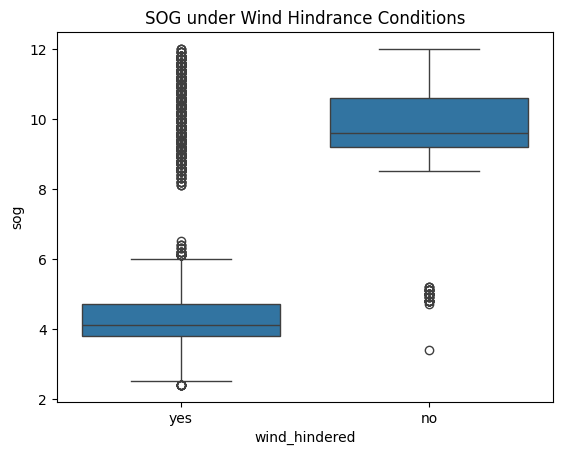

In [8]:
import mysql.connector
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# DB config
db_config = {
    "host": "localhost",
    "user": "root",
    "password": "AMS_ship_traj03",
    "database": "ship_data",
}

# Helper to query MySQL
def load_query(query):
    cnx = mysql.connector.connect(**db_config)
    df = pd.read_sql(query, cnx)
    cnx.close()
    return df

query = """
SELECT sog, wind_hindered,cog
FROM rhein_ais_polygon_env
WHERE sog IS NOT NULL AND wind_hindered IS NOT NULL and ship_type between 60 and 80
and navigational_status = 0 and visibility > 2000 and sog<30
"""
df = load_query(query)
df["direction"] = df["cog"].apply(lambda x: "inbound" if 180 <= x <= 360 else "outbound")
sns.boxplot(data=df, x="wind_hindered", y="sog")
plt.title("SOG under Wind Hindrance Conditions")
plt.show()




Speed Drop (ΔSOG) Relative to Unhindered

In [5]:
grouped = df.groupby(["wind_hindered"])["sog"].agg(["mean", "count"]).reset_index()
unhindered_mean = grouped.query("wind_hindered == 'no'")["mean"].values[0]
grouped["delta_sog"] = grouped["mean"] - unhindered_mean
grouped


,wind_hindered,mean,count,delta_sog
0,no,9.594050,605,0.000000
1,yes,4.969032,6342,-4.625018


In [6]:

grouped = df.groupby(["wind_hindered", "direction"])["sog"].agg(["mean", "count"]).reset_index()

baseline = grouped.query("wind_hindered == 'no' and direction == 'inbound'")["mean"].values[0]

grouped["delta_sog"] = grouped["mean"] - baseline
print(grouped)



  wind_hindered direction       mean  count  delta_sog
0            no   inbound   4.922500     40   0.000000
1            no  outbound   9.924779    565   5.002279
2           yes   inbound   4.057520   5379  -0.864980
3           yes  outbound  10.060436    963   5.137936


In [4]:


grouped = df.groupby(["wind_hindered", "direction"])["sog"].agg(["mean", "count"]).reset_index()
# Get baseline mean per direction (only rows with no hindrance)
baseline_df = (
    grouped
    .query("wind_hindered == 'no' ")
    [['direction', 'mean']]
    .rename(columns={'mean': 'baseline_mean'})
)

# Merge baseline means back onto grouped by direction
grouped = grouped.merge(baseline_df, on='direction', how='left')

# Calculate delta_sog relative to direction-specific baseline
grouped['delta_sog'] = grouped['mean'] - grouped['baseline_mean']

# Print the final table
print(grouped)

  wind_hindered direction       mean  count  baseline_mean  delta_sog
0            no   inbound   4.922500     40       4.922500   0.000000
1            no  outbound   9.924779    565       9.924779   0.000000
2           yes   inbound   4.057520   5379       4.922500  -0.864980
3           yes  outbound  10.060436    963       9.924779   0.135657


SOG by Wind Hindrance and Direction

C:\Users\cvais\AppData\Local\Temp\ipykernel_5604\1019922182.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, cnx)


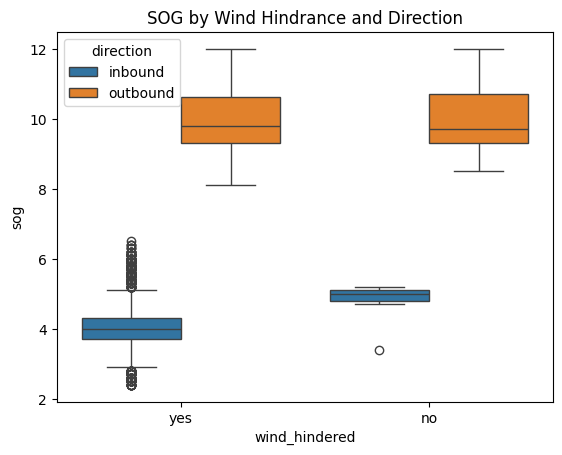

In [6]:
query = """
SELECT sog, cog, wind_hindered
FROM rhein_ais_polygon_env
WHERE sog IS NOT NULL AND cog IS NOT NULL and ship_type between 60 and 80
and navigational_status = 0 and sog<30;
"""
df = load_query(query)
df["direction"] = df["cog"].apply(lambda x: "inbound" if 180 <= x <= 360 else "outbound")

sns.boxplot(data=df, x="wind_hindered", y="sog", hue="direction")
plt.title("SOG by Wind Hindrance and Direction")
plt.show()


Wind allignment check

In [9]:
query = """
SELECT sog, cog, wind_direction_10m, wind_hindered
FROM rhein_ais_polygon_env
WHERE sog IS NOT NULL 
  AND cog IS NOT NULL 
  AND wind_direction_10m IS NOT NULL
  AND ship_type BETWEEN 60 AND 80
  AND navigational_status = 0
  and sog < 30;
"""
df = load_query(query)

df.columns = df.columns.str.lower()
df["direction"] = df["cog"].apply(lambda x: "inbound" if 180 <= x <= 360 else "outbound")
print(df.columns)



Index(['sog', 'cog', 'wind_direction_10m', 'wind_hindered', 'direction'], dtype='object')


C:\Users\cvais\AppData\Local\Temp\ipykernel_13236\1019922182.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, cnx)


In [11]:
def classify_wind_alignment(cog, wind_dir):
    angle = (wind_dir - cog + 360) % 360
    if angle <= 45 or angle >= 315:
        return "tailwind"
    elif 135 <= angle <= 225:
        return "headwind"
    else:
        return "crosswind"

df["wind_alignment"] = df.apply(lambda r: classify_wind_alignment(r["cog"], r["wind_direction_10m"]), axis=1)


SOG by Wind Alignment and Inbound/Outbound

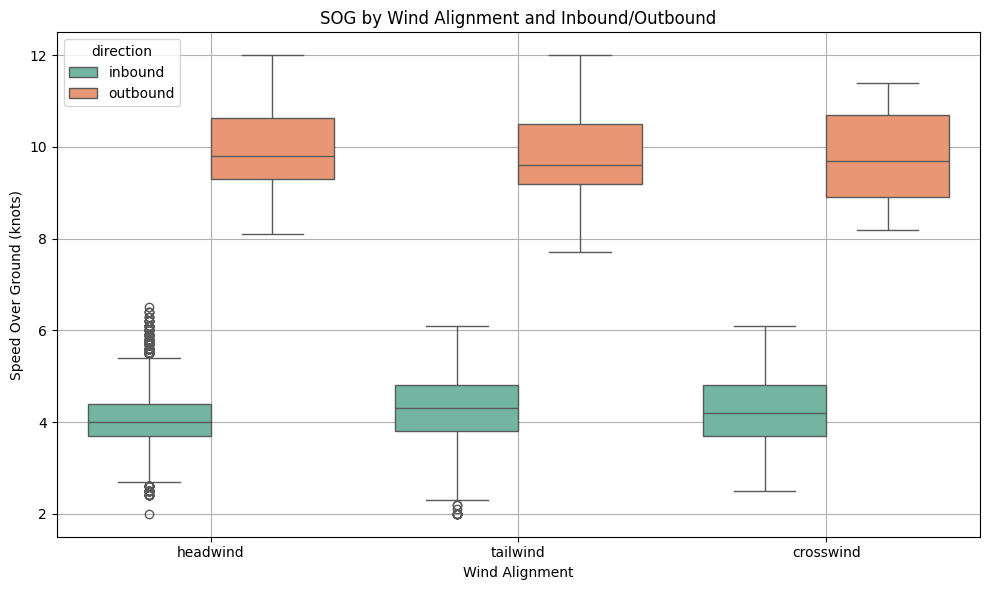

                          mean  median  count
direction wind_alignment                     
inbound   crosswind       4.26     4.2   1226
          headwind        4.06     4.0   6740
          tailwind        4.31     4.3   3693
outbound  crosswind       9.78     9.7    543
          headwind        9.96     9.8   1144
          tailwind        9.81     9.6   2878


In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="wind_alignment", y="sog", hue="direction", palette="Set2")
plt.title("SOG by Wind Alignment and Inbound/Outbound")
plt.ylabel("Speed Over Ground (knots)")
plt.xlabel("Wind Alignment")
plt.grid(True)
plt.tight_layout()
plt.show()

summary = (
    df.groupby(["direction", "wind_alignment"])["sog"]
      .agg(["mean", "median", "count"])
      .round(2)
)
print(summary)


SOG over Time under Wind Hindrance

C:\Users\cvais\AppData\Local\Temp\ipykernel_3616\3717629667.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, cnx)


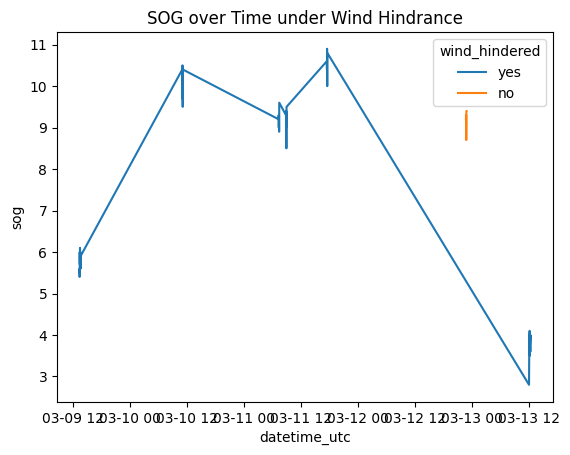

In [20]:
# SOG over time
query = """
SELECT datetime_utc, sog, wind_hindered
FROM rhein_ais_polygon_env
WHERE datetime_utc IS NOT NULL AND wind_hindered IS NOT NULL and ship_type =70
"""
df = load_query(query)

df["datetime_utc"] = pd.to_datetime(df["datetime_utc"])
sns.lineplot(data=df, x="datetime_utc", y="sog", hue="wind_hindered")
plt.title("SOG over Time under Wind Hindrance")
plt.show()



C:\Users\cvais\AppData\Local\Temp\ipykernel_13236\1019922182.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, cnx)


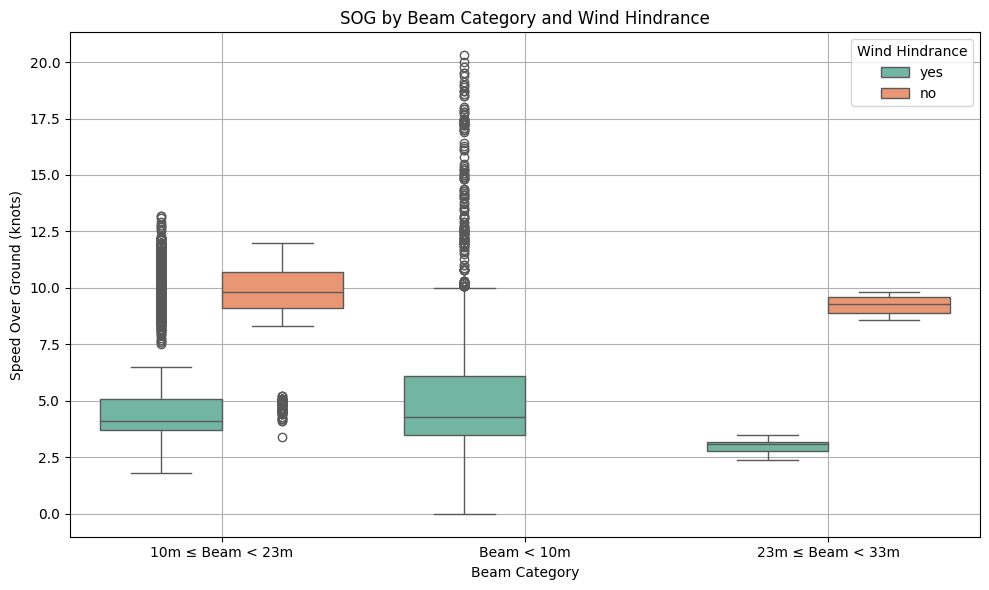


 Median SOG by Beam Category and Wind Hindrance:
wind_hindered      no  yes
beam_category             
10m ≤ Beam < 23m  9.8  4.1
23m ≤ Beam < 33m  9.3  3.1
Beam < 10m        NaN  4.3

 Mean SOG by Beam Category and Wind Hindrance:
      beam_category wind_hindered      mean  count
0  10m ≤ Beam < 23m            no  9.501613    868
1  10m ≤ Beam < 23m           yes  5.213633   8597
2  23m ≤ Beam < 33m            no  9.256667     60
3  23m ≤ Beam < 33m           yes  3.046207    145
4        Beam < 10m           yes  5.659413   1737


Text(0.5, 1.05, 'Median SOG by Beam, Direction, and Wind Hindrance')

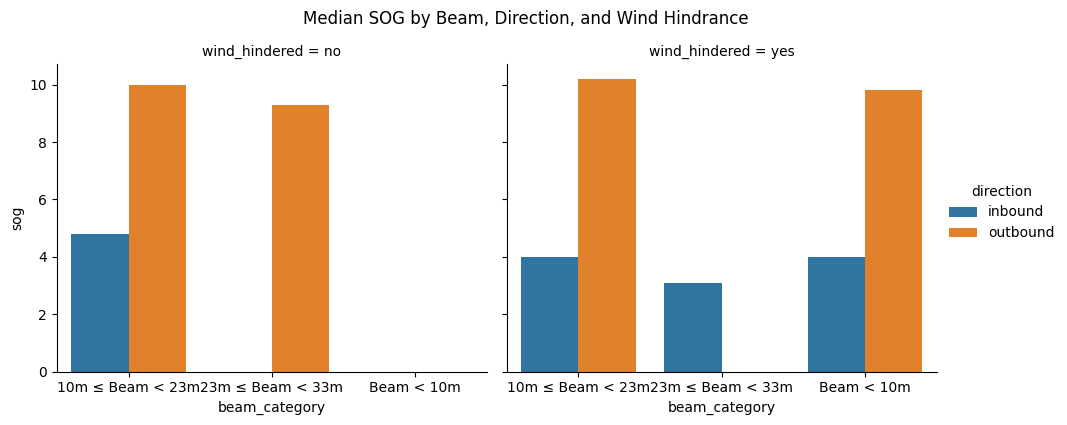

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

query = """
SELECT sog,cog, wind_hindered, beam_category
FROM rhein_ais_polygon_env
WHERE sog IS NOT NULL AND beam_category IS NOT NULL 
and navigational_status = 0
and sog<30
"""
df = load_query(query)


# 1.  Boxplot of SOG vs. Beam Category under Wind Hindrance
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="beam_category", y="sog", hue="wind_hindered", palette="Set2")
plt.title("SOG by Beam Category and Wind Hindrance")
plt.ylabel("Speed Over Ground (knots)")
plt.xlabel("Beam Category")
plt.grid(True)
plt.legend(title="Wind Hindrance")
plt.tight_layout()
plt.show()


# 3.  Print mean SOG values by beam category and wind/current hindrance
print("\n Median SOG by Beam Category and Wind Hindrance:")
df["direction"] = df["cog"].apply(lambda x: "inbound" if 180 <= x <= 360 else "outbound")
print (df.groupby(["beam_category", "wind_hindered"])["sog"].median().unstack())

print("\n Mean SOG by Beam Category and Wind Hindrance:")
print(df.groupby(["beam_category", "wind_hindered"])["sog"].agg(['mean', 'count']).reset_index())


df["direction"] = df["cog"].apply(lambda x: "inbound" if 180 <= x <= 360 else "outbound")
df.groupby(["beam_category", "wind_hindered", "direction"])["sog"].mean().unstack()


df_plot = df.groupby(["beam_category", "wind_hindered", "direction"])["sog"].median().reset_index()
sns.catplot(data=df_plot, x="beam_category", y="sog", hue="direction", col="wind_hindered", kind="bar", height=4, aspect=1.2)
plt.suptitle("Median SOG by Beam, Direction, and Wind Hindrance", y=1.05)


wind direction check

In [31]:
import numpy as np
import pandas as pd


query = """
SELECT sog,cog, wind_hindered, beam_category,wind_direction_10m
FROM rhein_ais_polygon_env
WHERE sog IS NOT NULL AND beam_category IS NOT NULL and ship_type between 60 and 80
and navigational_status = 0
"""
df = load_query(query)

df = df[(df["sog"] >= 3) & (df["sog"] <= 20)]
# Calculate relative wind angle (wind direction relative to vessel course)
df['rel_wind_angle'] = (df['wind_direction_10m'] - df['cog']) % 360

# Convert to -180 to 180 range for better interpretation
df['rel_wind_angle_180'] = df['rel_wind_angle'].apply(lambda x: x - 360 if x > 180 else x)

# Categorize relative wind direction
def categorize_wind_angle(angle):
    if -30 <= angle <= 30:
        return 'Headwind'
    elif 60 <= angle <= 120 or -120 <= angle <= -60:
        return 'Beam wind'
    elif angle >= 150 or angle <= -150:
        return 'Following wind'
    else:
        return 'Other'

df['wind_category'] = df['rel_wind_angle_180'].apply(categorize_wind_angle)

# Group by beam category, wind category, and wind hindrance, then calculate mean SOG and counts
result = df.groupby(['beam_category', 'wind_category', 'wind_hindered']).agg(
    mean_sog = ('sog', 'mean'),
    count = ('sog', 'count')
).reset_index()

print(result)


      beam_category   wind_category wind_hindered  mean_sog  count
0  10m ≤ Beam < 23m  Following wind           yes  5.175789   5035
1  10m ≤ Beam < 23m        Headwind            no  9.866667    405
2  10m ≤ Beam < 23m           Other            no  8.950000    140
3  10m ≤ Beam < 23m           Other           yes  4.513679    636
4  23m ≤ Beam < 33m  Following wind           yes  3.220482     83
5  23m ≤ Beam < 33m        Headwind            no  9.222917     48
6  23m ≤ Beam < 33m           Other            no  9.391667     12
7  23m ≤ Beam < 33m           Other           yes  3.188235     17
8        Beam < 10m  Following wind           yes  5.700000    576
9        Beam < 10m           Other           yes  8.226316     38


C:\Users\cvais\AppData\Local\Temp\ipykernel_3616\3717629667.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, cnx)


hinderance penalty

wind_hindered     beam_category wind_category        no       yes  delta_sog
2              10m ≤ Beam < 23m         Other  8.950000  4.513679   4.436321
5              23m ≤ Beam < 33m         Other  9.391667  3.188235   6.203431


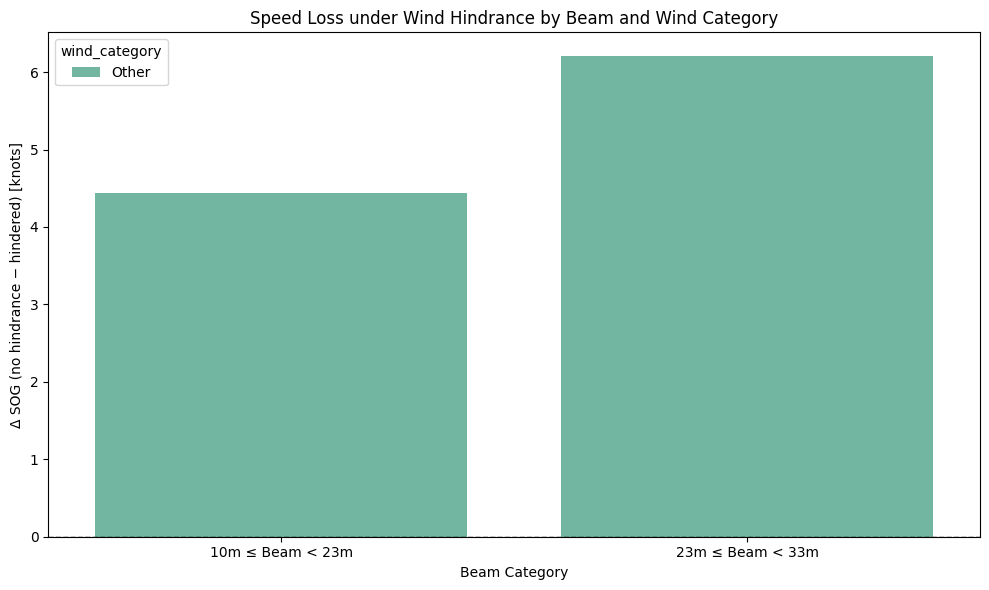

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Columns: beam_category, wind_category, wind_hindered, mean_sog

# Group raw data by beam, wind, hindrance
# Start from grouped values
df_grouped = (
    df.groupby(["beam_category", "wind_category", "wind_hindered"])["sog"]
      .mean()
      .reset_index(name="mean_sog")
)

# Pivot into wide format (no/yes side by side)
pivot = df_grouped.pivot_table(
    index=["beam_category", "wind_category"],
    columns="wind_hindered",
    values="mean_sog"
).reset_index()

# Keep only rows where both yes & no exist
pivot = pivot.dropna(subset=["no", "yes"])

# Compute delta
pivot["delta_sog"] = pivot["no"] - pivot["yes"]

print(pivot)

# Plot
plt.figure(figsize=(10,6))
sns.barplot(
    data=pivot,
    x="beam_category",
    y="delta_sog",
    hue="wind_category",
    palette="Set2"
)
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.ylabel("Δ SOG (no hindrance − hindered) [knots]")
plt.xlabel("Beam Category")
plt.title("Speed Loss under Wind Hindrance by Beam and Wind Category")
plt.tight_layout()
plt.show()



C:\Users\cvais\AppData\Local\Temp\ipykernel_3616\125897093.py:28: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, cnx)
C:\Users\cvais\AppData\Local\Temp\ipykernel_3616\125897093.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="visibility_class", y="sog", palette="coolwarm")


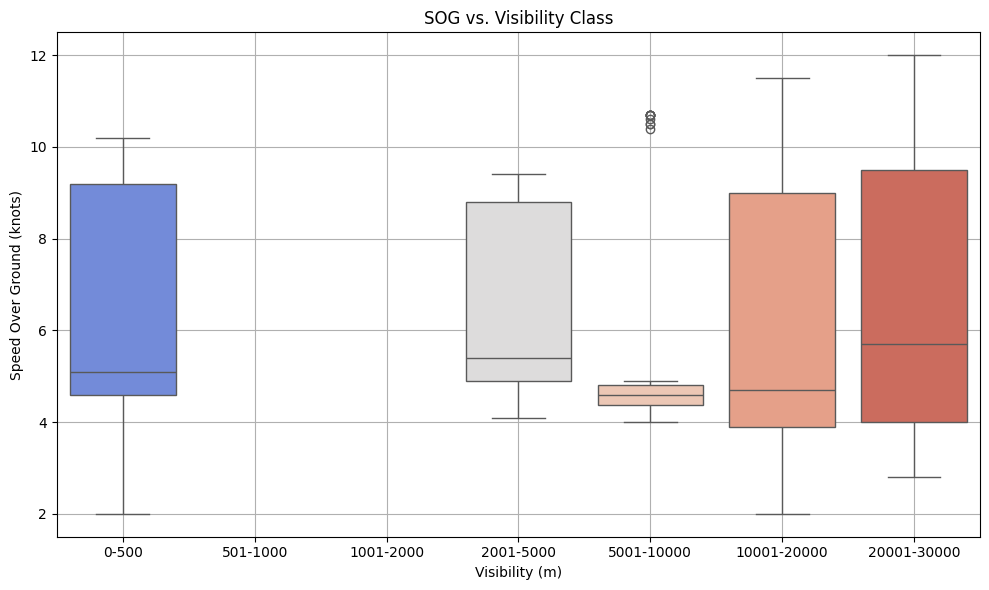


📊 Mean, Median, Count SOG by Visibility Class:
  visibility_class      mean  median  count
0            0-500  6.005079     5.1    571
1        2001-5000  6.480669     5.4    269
2       5001-10000  4.996875     4.6    128
3      10001-20000  5.859897     4.7   2521
4      20001-30000  6.728830     5.7   1710

🚢 Ship Types in Each Visibility Class:
  visibility_class ship_types_present
0            0-500           [70, 79]
1        2001-5000               [79]
2       5001-10000               [79]
3      10001-20000       [70, 74, 79]
4      20001-30000           [70, 79]


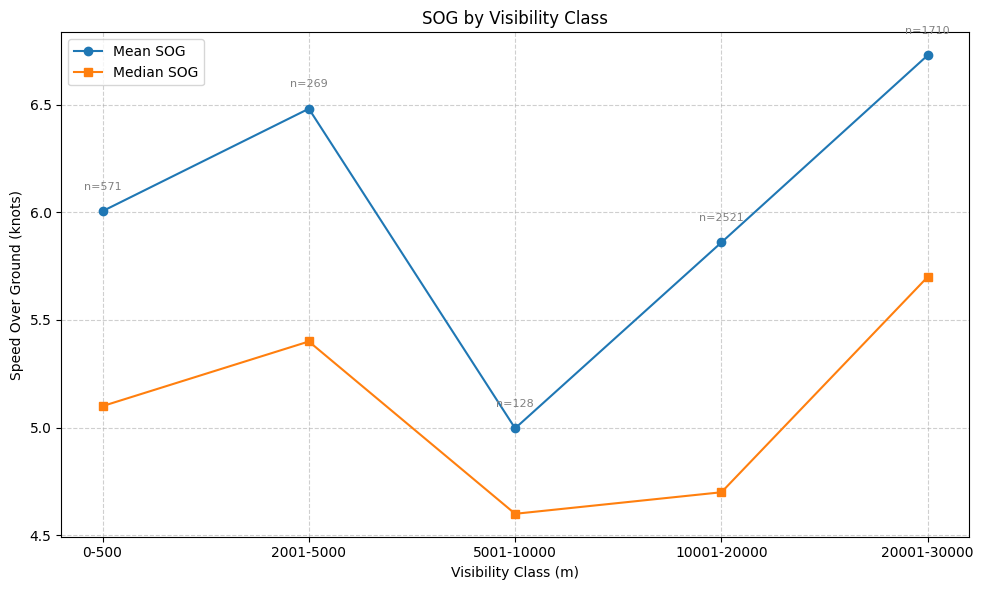


📊 Mean, Median, Count SOG by Visibility × Direction (Cargo):
  visibility_class direction       mean  median  count
0            0-500   inbound   4.418718     4.8    390
1            0-500  outbound   9.423204     9.4    181
2        2001-5000   inbound   5.051744     5.0    172
3        2001-5000  outbound   9.014433     9.1     97
4       5001-10000   inbound   4.520339     4.6    118
5       5001-10000  outbound  10.620000    10.7     10
6      10001-20000   inbound   4.262372     4.2   1762
7      10001-20000  outbound   9.568511     9.4    759
8      20001-30000   inbound   4.192291     4.0    921
9      20001-30000  outbound   9.689734     9.5    789


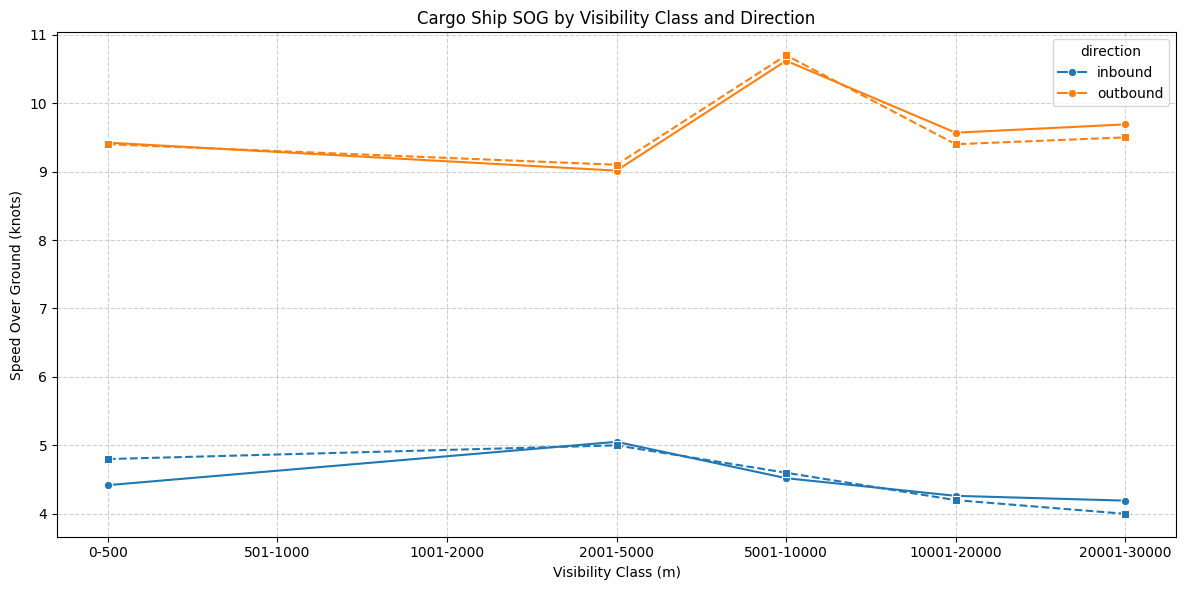


📊 Filtered Mean, Median, Count SOG by Visibility × Direction (Cargo):
  visibility_class direction      mean  median  count
0            0-500   inbound  4.418718     4.8    390
1            0-500  outbound  9.423204     9.4    181
2        2001-5000   inbound  5.051744     5.0    172
3        2001-5000  outbound  9.014433     9.1     97
4       5001-10000   inbound  4.520339     4.6    118
6      10001-20000   inbound  4.262372     4.2   1762
7      10001-20000  outbound  9.568511     9.4    759
8      20001-30000   inbound  4.192291     4.0    921
9      20001-30000  outbound  9.689734     9.5    789


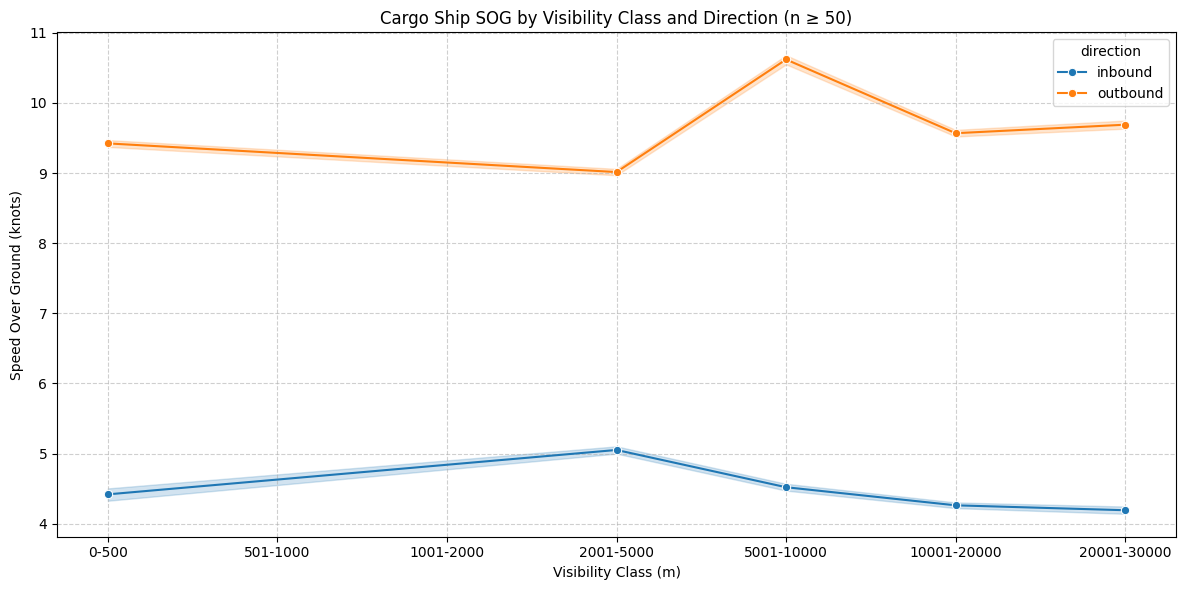

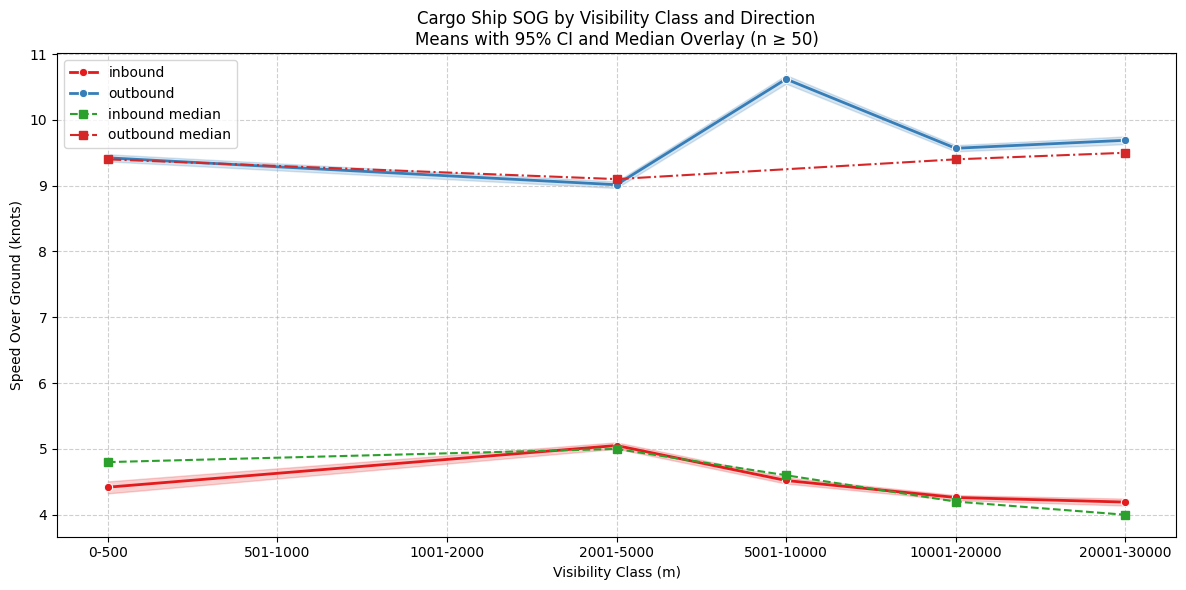

In [ ]:
import mysql.connector
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# --- DB config ---
db_config = {
    "host": "localhost",
    "user": "root",
    "password": "AMS_ship_traj03",
    "database": "ship_data",
}

# --- Load relevant columns with filters ---
def load_visibility_data():
    cnx = mysql.connector.connect(**db_config)
    query = """
        SELECT sog, visibility, beam_category, ship_type, navigational_status,cog
        FROM rhein_ais_polygon_env
        WHERE visibility IS NOT NULL AND sog IS NOT NULL
            AND visibility < 30000 AND sog > 1.0
            AND navigational_status = 0
           AND ship_type BETWEEN 70 AND 79   -- cargo ships

            and ship_type not in (40,51)
            
    """
    df = pd.read_sql(query, cnx)
    cnx.close()
    return df

df = load_visibility_data()

# --- Bin visibility ---
df["visibility_class"] = pd.cut(
    df["visibility"],
    bins=[0, 500, 1000, 2000, 5000, 10000, 20000, 30000],
    labels=["0-500", "501-1000", "1001-2000", "2001-5000", "5001-10000", "10001-20000", "20001-30000"]
)

# --- Plot SOG by visibility class ---
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="visibility_class", y="sog", palette="coolwarm")
plt.title("SOG vs. Visibility Class")
plt.xlabel("Visibility (m)")
plt.ylabel("Speed Over Ground (knots)")
plt.grid(True)
plt.tight_layout()
plt.show()

# --- Grouped stats: mean, median, count ---
group_stats = df.groupby("visibility_class", observed=True)["sog"].agg(['mean', 'median', 'count']).reset_index()
print("\n📊 Mean, Median, Count SOG by Visibility Class:")
print(group_stats)

# --- Ship types per visibility class ---
ship_types_by_bin = df.groupby("visibility_class", observed=True)["ship_type"].apply(lambda x: sorted(x.unique().tolist())).reset_index()
ship_types_by_bin.rename(columns={"ship_type": "ship_types_present"}, inplace=True)
print("\n🚢 Ship Types in Each Visibility Class:")
print(ship_types_by_bin)

import matplotlib.pyplot as plt

# Columns: visibility_class, mean, median, count

plt.figure(figsize=(10,6))

# Plot mean
plt.plot(group_stats["visibility_class"], group_stats["mean"], marker="o", label="Mean SOG", color="tab:blue")

# Plot median
plt.plot(group_stats["visibility_class"], group_stats["median"], marker="s", label="Median SOG", color="tab:orange")

# Add counts as text annotations above mean points
for i, row in group_stats.iterrows():
    plt.text(i, row["mean"]+0.1, f"n={row['count']}", ha="center", fontsize=8, color="gray")

plt.title("SOG by Visibility Class")
plt.xlabel("Visibility Class (m)")
plt.ylabel("Speed Over Ground (knots)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()
# Load cargo-only data

# Bin visibility
df["visibility_class"] = pd.cut(
    df["visibility"],
    bins=[0, 500, 1000, 2000, 5000, 10000, 20000, 30000],
    labels=["0-500", "501-1000", "1001-2000", "2001-5000", "5001-10000", "10001-20000", "20001-30000"]
)

# Add inbound/outbound based on COG
df["direction"] = df["cog"].apply(lambda x: "inbound" if 180 <= x <= 360 else "outbound")

# Group stats
stats = (
    df.groupby(["visibility_class", "direction"], observed=True)["sog"]
    .agg(["mean", "median", "count"])
    .reset_index()
)
print("\n📊 Mean, Median, Count SOG by Visibility × Direction (Cargo):")
print(stats)

# Plot
plt.figure(figsize=(12,6))
sns.lineplot(
    data=stats,
    x="visibility_class",
    y="mean",
    hue="direction",
    marker="o"
)
sns.lineplot(
    data=stats,
    x="visibility_class",
    y="median",
    hue="direction",
    marker="s",
    linestyle="--",
    legend=False
)

plt.title("Cargo Ship SOG by Visibility Class and Direction")
plt.ylabel("Speed Over Ground (knots)")
plt.xlabel("Visibility Class (m)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

import seaborn as sns
import matplotlib.pyplot as plt

# Start from grouped stats (df_stats)
df_stats = df.groupby(
    ["visibility_class", "direction"], observed=True
)["sog"].agg(["mean", "median", "count"]).reset_index()

# ✅ Filter out low-sample bins (e.g., keep only count >= 50)
df_stats = df_stats[df_stats["count"] >= 50]

print("\n📊 Filtered Mean, Median, Count SOG by Visibility × Direction (Cargo):")
print(df_stats)

# --- Plot with seaborn lineplot + CI ---
plt.figure(figsize=(12,6))

sns.lineplot(
    data=df[df["visibility_class"].notna()],  # raw data for CI calc
    x="visibility_class",
    y="sog",
    hue="direction",
    errorbar="ci",   # 95% confidence interval
    marker="o"
)

plt.title("Cargo Ship SOG by Visibility Class and Direction (n ≥ 50)")
plt.ylabel("Speed Over Ground (knots)")
plt.xlabel("Visibility Class (m)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12,6))

# Lineplot with CI bands (mean ± 95% CI)
sns.lineplot(
    data=df[df["visibility_class"].notna()],
    x="visibility_class",
    y="sog",
    hue="direction",
    errorbar="ci",
    marker="o",
    linewidth=2,
    palette="Set1"
)

# Overlay medians from grouped stats (dashed lines)
for direction, style in zip(["inbound", "outbound"], ["--", "-."]):
    subset = df_stats[df_stats["direction"] == direction]
    plt.plot(
        subset["visibility_class"],
        subset["median"],
        linestyle=style,
        marker="s",
        label=f"{direction} median"
    )

plt.title("Cargo Ship SOG by Visibility Class and Direction\nMeans with 95% CI and Median Overlay (n ≥ 50)")
plt.ylabel("Speed Over Ground (knots)")
plt.xlabel("Visibility Class (m)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


In [15]:
import pandas as pd
import mysql.connector

# DB config
db_config = {
    "host": "localhost",
    "user": "root",
    "password": "AMS_ship_traj03",
    "database": "ship_data",
}

# Load encounter table
def load_encounters():
    cnx = mysql.connector.connect(**db_config)
    df = pd.read_sql("SELECT * FROM ais_open_water_polygon_enc", cnx)  # replace with actual name
    cnx.close()
    return df

# Load environment table
def load_environment():
    cnx = mysql.connector.connect(**db_config)
    df = pd.read_sql("SELECT id, sog, wind_hindered, visibility FROM rhein_ais_polygon_env", cnx)
    cnx.close()
    return df

enc_df = load_encounters()
env_df = load_environment()


# Ensure id_1 and id_2 are integers for merging
enc_df["id_1"] = enc_df["id_1"].astype(int)
enc_df["id_2"] = enc_df["id_2"].astype(int)

# Merge environmental data for both ship1 and ship2
enc_df = enc_df.merge(env_df.add_suffix("_1"), left_on="id_1", right_on="id_1", how="left")
enc_df = enc_df.merge(env_df.add_suffix("_2"), left_on="id_2", right_on="id_2", how="left")


# Hindrance if either ship is affected
enc_df["wind_hindered"] = enc_df["wind_hindered_1"].eq("yes") | enc_df["wind_hindered_2"].eq("yes")
enc_df["low_visibility"] = (enc_df["visibility_1"] < 2000) | (enc_df["visibility_2"] < 2000)

# Average SOG
enc_df["avg_sog"] = (enc_df["sog_1"] + enc_df["sog_2"]) / 2


# Summary by encounter type and hindrance
summary = enc_df.groupby(["encounter_type", "wind_hindered", "low_visibility"]).agg(
    encounter_count=("id_1", "count"),
    mean_sog=("avg_sog", "mean")
).reset_index()

print(summary)



       encounter_type  wind_hindered  low_visibility  encounter_count  \
0       crossing_port          False           False               31   
1  crossing_starboard          False           False                7   
2             head-on          False           False                7   
3          overtaking          False           False                7   

   mean_sog  
0       NaN  
1       NaN  
2       NaN  
3       NaN  


C:\Users\cvais\AppData\Local\Temp\ipykernel_13236\50307148.py:15: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql("SELECT * FROM ais_open_water_polygon_enc", cnx)  # replace with actual name
C:\Users\cvais\AppData\Local\Temp\ipykernel_13236\50307148.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql("SELECT id, sog, wind_hindered, visibility FROM rhein_ais_polygon_env", cnx)


c:\Users\cvais\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\matrix.py:202: RuntimeWarning: All-NaN slice encountered
  vmin = np.nanmin(calc_data)
c:\Users\cvais\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\matrix.py:207: RuntimeWarning: All-NaN slice encountered
  vmax = np.nanmax(calc_data)


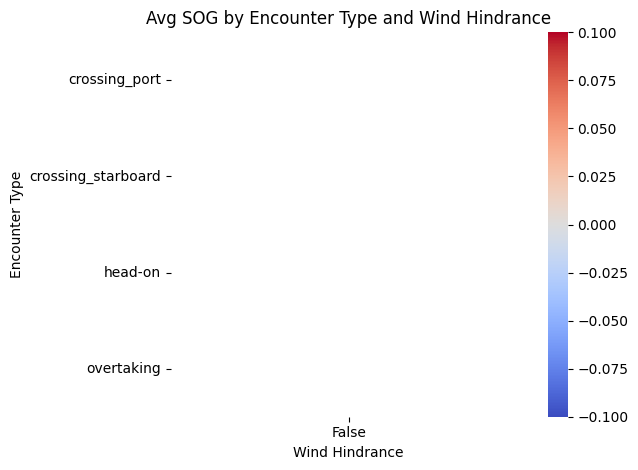

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

pivot = enc_df.groupby(["encounter_type", "wind_hindered"])["avg_sog"].mean().unstack()
sns.heatmap(pivot, annot=True, cmap="coolwarm")
plt.title("Avg SOG by Encounter Type and Wind Hindrance")
plt.xlabel("Wind Hindrance")
plt.ylabel("Encounter Type")
plt.tight_layout()
plt.show()


wind_hindered
no     0.018597
yes    0.018977
Name: turn_rate, dtype: float64


C:\Users\cvais\AppData\Local\Temp\ipykernel_13236\2875101175.py:19: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, cnx)


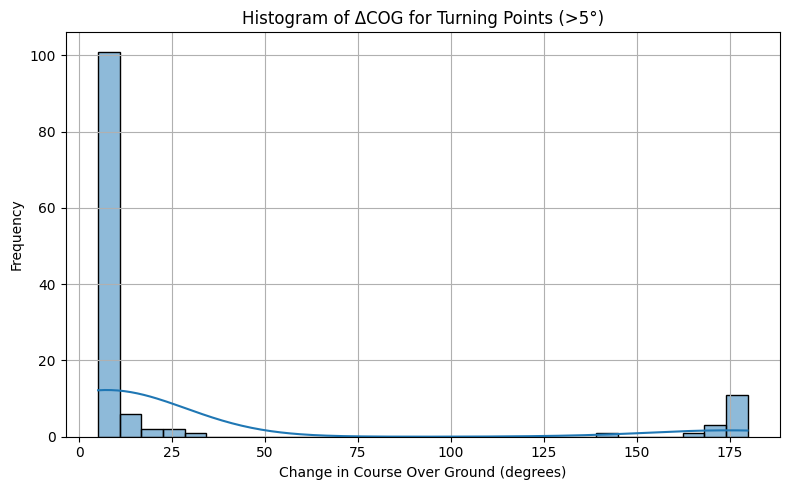

In [17]:
import mysql.connector
import pandas as pd

db_config = {
    "host": "localhost",
    "user": "root",
    "password": "AMS_ship_traj03",
    "database": "ship_data",
}

def load_cog_data():
    cnx = mysql.connector.connect(**db_config)
    query = """
        SELECT mmsi, datetime_utc, cog, wind_hindered,sog
        FROM rhein_ais_polygon_env
        WHERE cog IS NOT NULL AND wind_hindered IS NOT NULL and ship_type between 60 and 80 and navigational_status = 0
        ORDER BY mmsi, datetime_utc
    """
    df = pd.read_sql(query, cnx)
    cnx.close()
    return df

df = load_cog_data()


# Ensure correct type and sorting
df["datetime_utc"] = pd.to_datetime(df["datetime_utc"])
df.sort_values(by=["mmsi", "datetime_utc"], inplace=True)

# Compute ΔCOG
df["delta_cog"] = df.groupby("mmsi")["cog"].diff().abs()

# Normalize wrap-around values (>180° becomes 360 - Δ)
df["delta_cog"] = df["delta_cog"].apply(lambda x: 360 - x if x > 180 else x)

TURN_THRESHOLD = 5  # degrees

df["is_turn"] = df["delta_cog"] > TURN_THRESHOLD

turn_summary = df.groupby(["mmsi", "wind_hindered"]).agg(
    total_points=("delta_cog", "count"),
    turn_count=("is_turn", "sum")
).reset_index()

turn_summary["turn_rate"] = turn_summary["turn_count"] / turn_summary["total_points"]


print(turn_summary.groupby("wind_hindered")["turn_rate"].mean())

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.histplot(df[df["is_turn"]]["delta_cog"], bins=30, kde=True)
plt.title("Histogram of ΔCOG for Turning Points (>5°)")
plt.xlabel("Change in Course Over Ground (degrees)")
plt.ylabel("Frequency")
plt.grid(True)
plt.tight_layout()
plt.show()


Text(0.5, 1.0, 'Turn Angle (ΔCOG) Distribution by Wind Hindrance')

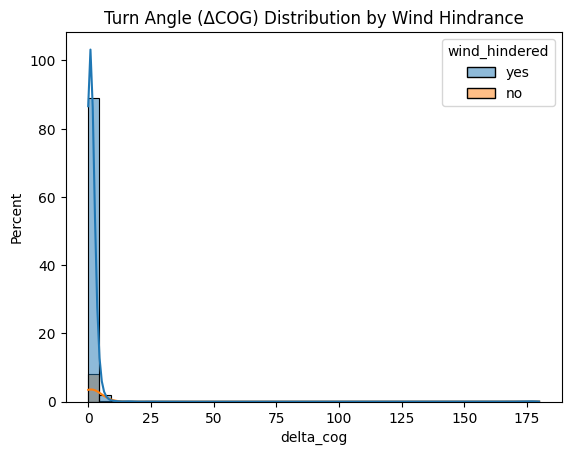

In [18]:
sns.histplot(data=df, x="delta_cog", bins=40, hue="wind_hindered", kde=True, stat="percent")
plt.title("Turn Angle (ΔCOG) Distribution by Wind Hindrance")


Text(0.5, 0, 'Wind Hindrance')

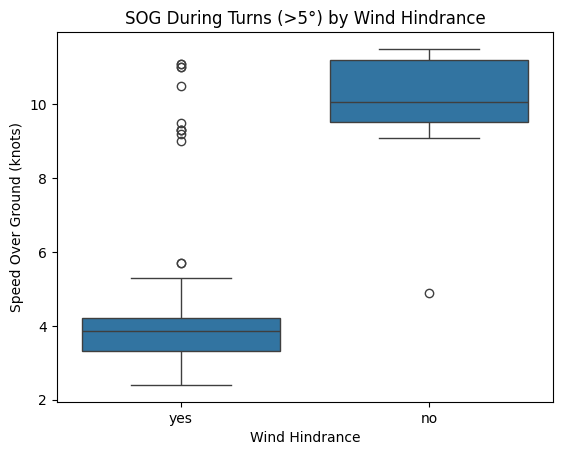

In [19]:
df_turns = df[df["is_turn"]]
sns.boxplot(data=df_turns, x="wind_hindered", y="sog")
plt.title("SOG During Turns (>5°) by Wind Hindrance")
plt.ylabel("Speed Over Ground (knots)")
plt.xlabel("Wind Hindrance")


cog vs turn

In [20]:
import mysql.connector
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns

db_config = {
    "host": "localhost",
    "user": "root",
    "password": "AMS_ship_traj03",
    "database": "ship_data",
}

# --- Load AIS + wind for Rhine haven bounding box ---
def load_rhine_data():
    cnx = mysql.connector.connect(**db_config)
    query = """
        SELECT mmsi, datetime_utc, cog, sog,
               wind_direction_10m, beam_category
        FROM rhein_ais_polygon_env
        WHERE cog IS NOT NULL 
          AND wind_direction_10m IS NOT NULL
          AND ship_type between 60 and 80
          AND navigational_status = 0
        ORDER BY mmsi, datetime_utc
    """
    df = pd.read_sql(query, cnx)
    cnx.close()
    return df

df = load_rhine_data()

# --- ΔCOG + turn classification ---
df["datetime_utc"] = pd.to_datetime(df["datetime_utc"])
df.sort_values(by=["mmsi", "datetime_utc"], inplace=True)

df["delta_cog"] = df.groupby("mmsi")["cog"].diff().abs()
df["delta_cog"] = df["delta_cog"].apply(lambda x: 360 - x if x > 180 else x)

TURN_THRESHOLD = 5
df["is_turn"] = (df["delta_cog"] > TURN_THRESHOLD).astype(int)

# --- Wind alignment wrt COG ---
def classify_wind_alignment(cog, wind_dir):
    if pd.isna(cog) or pd.isna(wind_dir):
        return np.nan
    angle = (wind_dir - cog + 360) % 360
    if angle <= 45 or angle >= 315:
        return "tail"
    elif 135 <= angle <= 225:
        return "head"
    else:
        return "cross"

df["wind_align"] = df.apply(
    lambda r: classify_wind_alignment(r["cog"], r["wind_direction_10m"]), axis=1
)

# --- Speed bands ---
df["sog_band"] = pd.cut(
    df["sog"], bins=[0,6,9,12,15,40],
    labels=["<=6","6–9","9–12","12–15",">15"]
)

# Drop missing
df = df.dropna(subset=["wind_align","beam_category","sog_band"])

# --- Descriptive: turn rates by wind alignment ---
turn_summary = (
    df.groupby(["wind_align","beam_category"])["is_turn"]
      .agg(["mean","count"]).reset_index()
)
print("\nTurn probability by wind alignment (Rhine haven):")
print(turn_summary)

# --- Logistic regression: wind only ---
model = smf.logit(
    "is_turn ~ C(wind_align) + C(beam_category) + C(sog_band)",
    data=df
).fit()

print(model.summary())
print(df["wind_alignment"].value_counts())
print(df["beam_category"].value_counts())
print(df["sog_band"].value_counts())
print(df["direction"].value_counts())
# Odds ratios
odds_ratios = pd.DataFrame({
    "OR": np.exp(model.params),
    "CI_lower": np.exp(model.conf_int()[0]),
    "CI_upper": np.exp(model.conf_int()[1])
})
print("\nOdds Ratios with 95% CI:\n", odds_ratios)

# --- Visualization ---
plt.figure(figsize=(8,5))
sns.barplot(data=turn_summary, x="wind_align", y="mean", hue="beam_category")
plt.title("Turn Probability by Wind Alignment and Ship Size (Rhine haven)")
plt.ylabel("Proportion of Turns")
plt.xlabel("Wind Alignment relative to COG")
plt.grid(True, axis="y")
plt.tight_layout()
plt.show()


C:\Users\cvais\AppData\Local\Temp\ipykernel_13236\3214770224.py:28: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, cnx)



Turn probability by wind alignment (Rhine haven):
  wind_align     beam_category      mean  count
0      cross  10m ≤ Beam < 23m  0.042945   1630
1      cross        Beam < 10m  0.028777    139
2       head  10m ≤ Beam < 23m  0.021158   6995
3       head  23m ≤ Beam < 33m  0.089655    145
4       head        Beam < 10m  0.025538    744
5       tail  10m ≤ Beam < 23m  0.031849   6154
6       tail  23m ≤ Beam < 33m  0.016667     60
7       tail        Beam < 10m  0.016807    357
Optimization terminated successfully.
         Current function value: 0.126267
         Iterations 8


LinAlgError: Singular matrix


Turn probability by wind alignment and direction:
  wind_align direction  turn_prob  count
0      cross   inbound   0.055465   1226
1      cross  outbound   0.011050    543
2       head   inbound   0.023442   6740
3       head  outbound   0.019231   1144
4       tail   inbound   0.037910   3693
5       tail  outbound   0.021890   2878

Speed by wind alignment and direction:
  wind_align direction  mean_sog  median_sog  count
0      cross   inbound  4.264437         4.2   1226
1      cross  outbound  9.783057         9.7    543
2       head   inbound  4.062789         4.0   6740
3       head  outbound  9.959615         9.8   1144
4       tail   inbound  4.307663         4.3   3693
5       tail  outbound  9.807158         9.6   2878


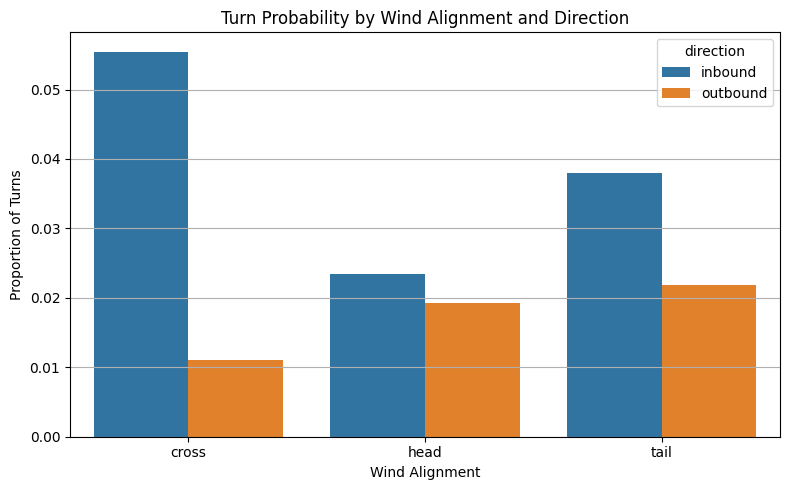

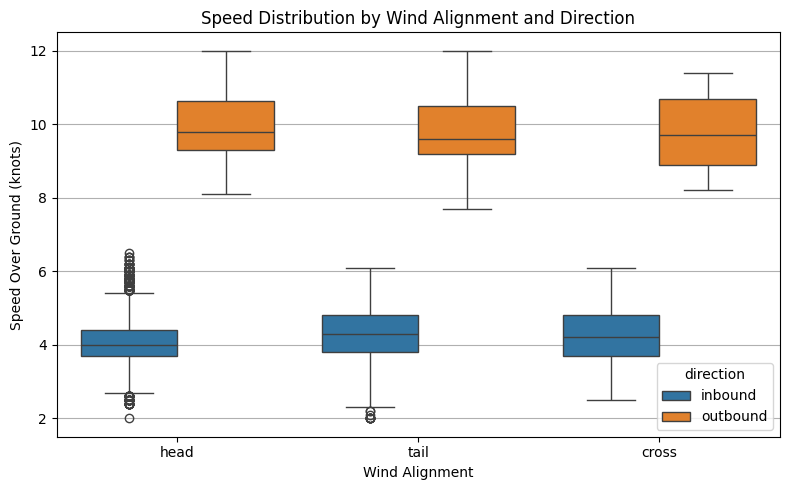


Turn probability by wind alignment and direction:
  wind_align direction  turn_prob  count
0      cross   inbound   0.055465   1226
1      cross  outbound   0.011050    543
2       head   inbound   0.023442   6740
3       head  outbound   0.019231   1144
4       tail   inbound   0.037910   3693
5       tail  outbound   0.021890   2878

Turn probability under headwind:
  direction  turn_prob  count
0   inbound   0.023442   6740
1  outbound   0.019231   1144

Speed under headwind:
  direction  mean_sog  median_sog  count
0   inbound  4.062789         4.0   6740
1  outbound  9.959615         9.8   1144


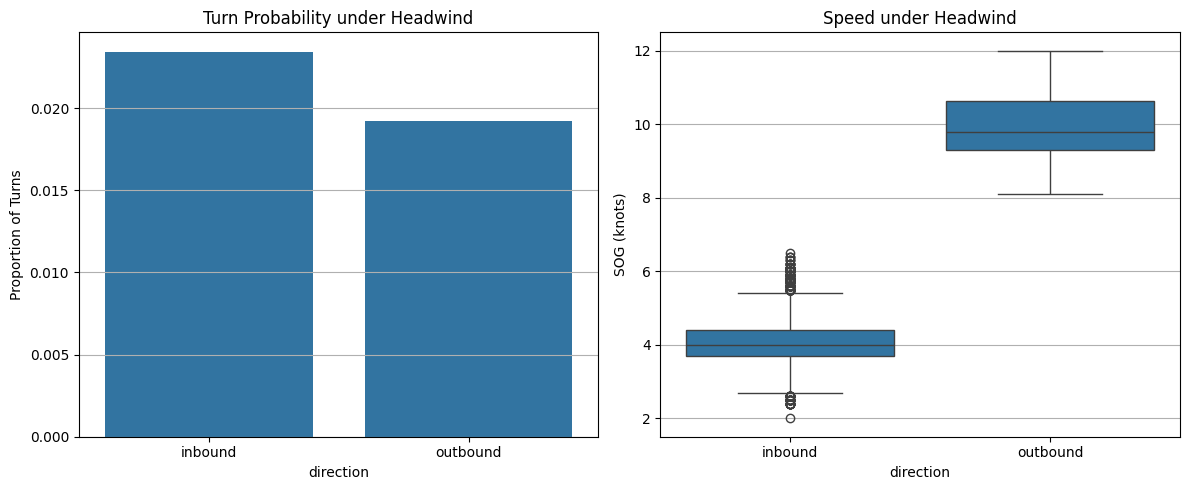

In [21]:
# --- Direction classification from COG ---
def classify_direction(cog):
    if pd.isna(cog):
        return np.nan
    return "inbound" if 180 <= cog <= 360 else "outbound"

df["direction"] = df["cog"].apply(classify_direction)

# --- Turn probability by wind + direction ---
turn_summary = (
    df.groupby(["wind_align","direction"])["is_turn"]
      .agg(turn_prob="mean", count="count")
      .reset_index()
)
print("\nTurn probability by wind alignment and direction:")
print(turn_summary)

# --- Average speed by wind + direction ---
sog_summary = (
    df.groupby(["wind_align","direction"])["sog"]
      .agg(mean_sog="mean", median_sog="median", count="count")
      .reset_index()
)
print("\nSpeed by wind alignment and direction:")
print(sog_summary)

# --- Visualization: Turn probability ---
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
sns.barplot(data=turn_summary, x="wind_align", y="turn_prob", hue="direction")
plt.title("Turn Probability by Wind Alignment and Direction")
plt.ylabel("Proportion of Turns")
plt.xlabel("Wind Alignment")
plt.grid(True, axis="y")
plt.tight_layout()
plt.show()

# --- Visualization: Speed ---
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="wind_align", y="sog", hue="direction")
plt.title("Speed Distribution by Wind Alignment and Direction")
plt.ylabel("Speed Over Ground (knots)")
plt.xlabel("Wind Alignment")
plt.grid(True, axis="y")
plt.tight_layout()
plt.show()
# --- Turn probability by wind + direction ---
turn_summary = (
    df.groupby(["wind_align","direction"])["is_turn"]
      .agg(turn_prob="mean", count="count")
      .reset_index()
)
print("\nTurn probability by wind alignment and direction:")
print(turn_summary)

# --- Focus only on headwind cases ---
headwind_df = df[df["wind_align"] == "head"].copy()

# Turn probability under headwind
turn_summary_head = (
    headwind_df.groupby("direction")["is_turn"]
               .agg(turn_prob="mean", count="count")
               .reset_index()
)
print("\nTurn probability under headwind:")
print(turn_summary_head)

# Speed under headwind
sog_summary_head = (
    headwind_df.groupby("direction")["sog"]
               .agg(mean_sog="mean", median_sog="median", count="count")
               .reset_index()
)
print("\nSpeed under headwind:")
print(sog_summary_head)

# --- Visualization ---
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12,5))

sns.barplot(data=turn_summary_head, x="direction", y="turn_prob", ax=axes[0])
axes[0].set_title("Turn Probability under Headwind")
axes[0].set_ylabel("Proportion of Turns")
axes[0].grid(True, axis="y")

sns.boxplot(data=headwind_df, x="direction", y="sog", ax=axes[1])
axes[1].set_title("Speed under Headwind")
axes[1].set_ylabel("SOG (knots)")
axes[1].grid(True, axis="y")

plt.tight_layout()
plt.show()

